# Agent Loops Study — Colab CPU Server Pipeline

This notebook runs the complete **Agent Loops Study (Phases 1 & 2)** on a **Google Colab CPU runtime** so that parsing 60,000+ trajectories, replaying loop detectors across 200 matched-random seeds, and running 1,000-replicate task-clustered bootstraps execute on remote CPUs without blocking your Mac.


## 1. Environment Check & Colab CPU Setup

Verify the active CPU server environment, install any missing packages, unpack the repository bundle on the remote Colab VM, and run the unit test suite.

In [ ]:
# @title 1. Setup Colab CPU Environment & Run Unit Tests
import importlib.util
import os
from pathlib import Path
import platform
import subprocess
import sys
import tarfile

print(f"Platform: {platform.platform()} | Python: {sys.version.split()[0]} | CPU cores: {os.cpu_count()}")

REQUIRED_PACKAGES = [
    "huggingface_hub",
    "pyarrow",
    "pandas",
    "numpy",
    "matplotlib",
    "orjson",
    "pytest",
    "requests",
    "tqdm",
    "scipy",
    "statsmodels",
]
missing = [pkg for pkg in REQUIRED_PACKAGES if importlib.util.find_spec(pkg) is None]
if missing:
    print(f"Installing missing packages: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

ROOT = Path.cwd()
bundle_path = Path("/content/code_bundle.tar.gz")
if not (ROOT / "src" / "agent_loops").exists() and bundle_path.exists():
    print(f"Extracting {bundle_path} into /content ...")
    with tarfile.open(bundle_path, "r:gz") as tf:
        tf.extractall("/content")
    ROOT = Path("/content")

if (ROOT / "src" / "agent_loops").exists():
    SRC_DIR = ROOT / "src"
elif Path("/Users/davidflorez/.gemini/jetski/scratch/agent-loops/src/agent_loops").exists():
    ROOT = Path("/Users/davidflorez/.gemini/jetski/scratch/agent-loops")
    SRC_DIR = ROOT / "src"
else:
    raise FileNotFoundError(f"Could not find src/agent_loops in {ROOT}.")

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
os.chdir(ROOT)
print(f"Working directory: {ROOT}")

import pytest
ret = pytest.main(["-q", str(ROOT / "tests")])
assert ret == 0, f"Pytest failed with exit code {ret}"


Platform: Linux-6.6.159+-x86_64-with-glibc2.39 | Python: 3.13.18 | CPU cores: 2
All required packages are already installed.
Extracting /content/code_bundle.tar.gz into /content ...
Working directory: /content


/tmp/ipykernel_1987/1075487626.py:37: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall("/content")


.

.

.

.

... (30 outputs left out)

.

.

                                     [100%]


=============================== warnings summary ===============================
tests/test_fair_study.py::test_regressions_and_sensitivity_run_end_to_end
tests/test_fair_study.py::test_regressions_and_sensitivity_run_end_to_end
tests/test_plots_and_article.py::test_phase2_plots_and_article_generation
tests/test_plots_and_article.py::test_phase2_plots_and_article_generation
  /usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
    return self._fit_irls(

tests/test_fair_study.py::test_regressions_and_sensitivity_run_end_to_end
  /usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
    wls_results = wls_model.fit(method=wls_method2)

tests/test_fair_study.py::test_regressions_and_sensitivity_run_end

## 2. Run Full Study Pipeline (Phases 1 & 2) and Display Visualizations

Executes `run_all.main()` (fixed seed `42`) on the Colab CPU VM and renders the summary table and all 6 publication plots inline.

[downloading] yoonholee/terminalbench-trajectories -> /content/data/terminalbench


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

[downloading] ibragim-bad/swe_rebench_07_2026_trajectories -> /content/data/swe_rebench_07_2026


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (104 outputs left out)

[stage 5] Fair Open-vs-Closed statistical study done in 644.91s



HEADLINE SUMMARY
# Agent Loops Study — Summary of Computed Findings

All numbers below are generated programmatically from cached public trajectory datasets (CPU-only offline pipeline, fixed seed `42`, 200 matched-random bootstrap seeds).

## 1. Headline Prevalence, Cost Share, and Pass Rates

| Metric | Terminal-Bench 2.0 | TB Clean-Trace Subset (0 RSC refs) | SWE-rebench July 2026 |
| --- | ---: | ---: | ---: |
| Trajectories analyzed (with steps) | 34,462 | 5,371 | 9,435 |
| Runs with any loop | 10,684 (31.00%) | 2,253 (41.95%) | 5,188 (54.99%) |
| Loop share of steps | 7.38% (79,344/1,075,547) | 12.31% | 4.11% (25,975/631,803) |
| Cost-validated runs | 5,011 | 3,787 | 6,844 |
| Loop share of cache-aware dollars | 17.71% ($589.76 / $3,330.95) | 14.94% | 2.87% ($215.10 / $7,506.20) |
| Pass rate: looping runs | 27.42% | 19.22% | 43.14% |
| Pass rate: loop-free runs | 34.27% | 24.47% | 59.17% |
| Productive repeat step share (excluded from loops) | 5.54% | 9.82% | 1.90% |
| Period-k 

,slice,cohort,runs,loop_runs,loop_run_rate,total_steps,loop_steps,loop_step_share,prod_repeat_step_share,mean_steps,...,error_streak_rate,reread_rate,prod_repeat_rate,det_gemini_cli,det_cline,det_openhands,det_openclaw_10,det_any_rule,any_rule_recall_on_loopers,gemini_cli_recall_on_loopers
0,terminalbench_steps_all,open_weights,11943,4569,0.382567,417563,40848,0.097825,0.075636,34.962991,...,0.090178,0.022189,0.561752,575,223,202,273,812,0.177719,0.125848
1,terminalbench_steps_all,closed,22519,6115,0.271548,657984,38496,0.058506,0.042534,29.219059,...,0.069630,0.014077,0.381145,205,185,145,209,407,0.066558,0.033524
2,terminalbench_terminus_2,open_weights,8003,2557,0.319505,271064,23283,0.085895,0.088651,33.870299,...,0.046483,0.030239,0.650131,181,180,120,167,302,0.118107,0.070786
3,terminalbench_terminus_2,closed,7938,1027,0.129378,137460,4197,0.030533,0.041510,17.316704,...,0.014865,0.016125,0.415218,67,67,46,26,82,0.079844,0.065239
4,terminalbench_openhands,open_weights,1730,1316,0.760694,93558,13808,0.147588,0.066045,54.079769,...,0.241618,0.006936,0.603468,43,20,41,98,145,0.110182,0.032675
5,terminalbench_openhands,closed,4325,2199,0.508439,209729,13146,0.062681,0.032823,48.492254,...,0.133410,0.011561,0.388671,34,14,43,89,139,0.063211,0.015462
6,terminalbench_mini_swe_agent,open_weights,1770,543,0.306780,16828,3033,0.180235,0.032921,9.507345,...,0.117514,0.004520,0.158757,348,20,39,5,359,0.661142,0.640884
7,terminalbench_mini_swe_agent,closed,4725,1573,0.332910,121365,15921,0.131183,0.064821,25.685714,...,0.106667,0.020741,0.321270,44,44,37,62,96,0.061030,0.027972
8,swe_rebench_all,open_weights,3885,3470,0.893179,367989,20819,0.056575,0.027729,94.720463,...,0.136422,0.261004,0.766281,402,19,32,6,417,0.120173,0.115850
9,swe_rebench_all,closed_all,5550,1718,0.309550,263814,5156,0.019544,0.006774,47.534054,...,0.127568,0.028649,0.194955,17,16,53,11,58,0.033760,0.009895


### `step_vs_dollar_share_per_model.png`

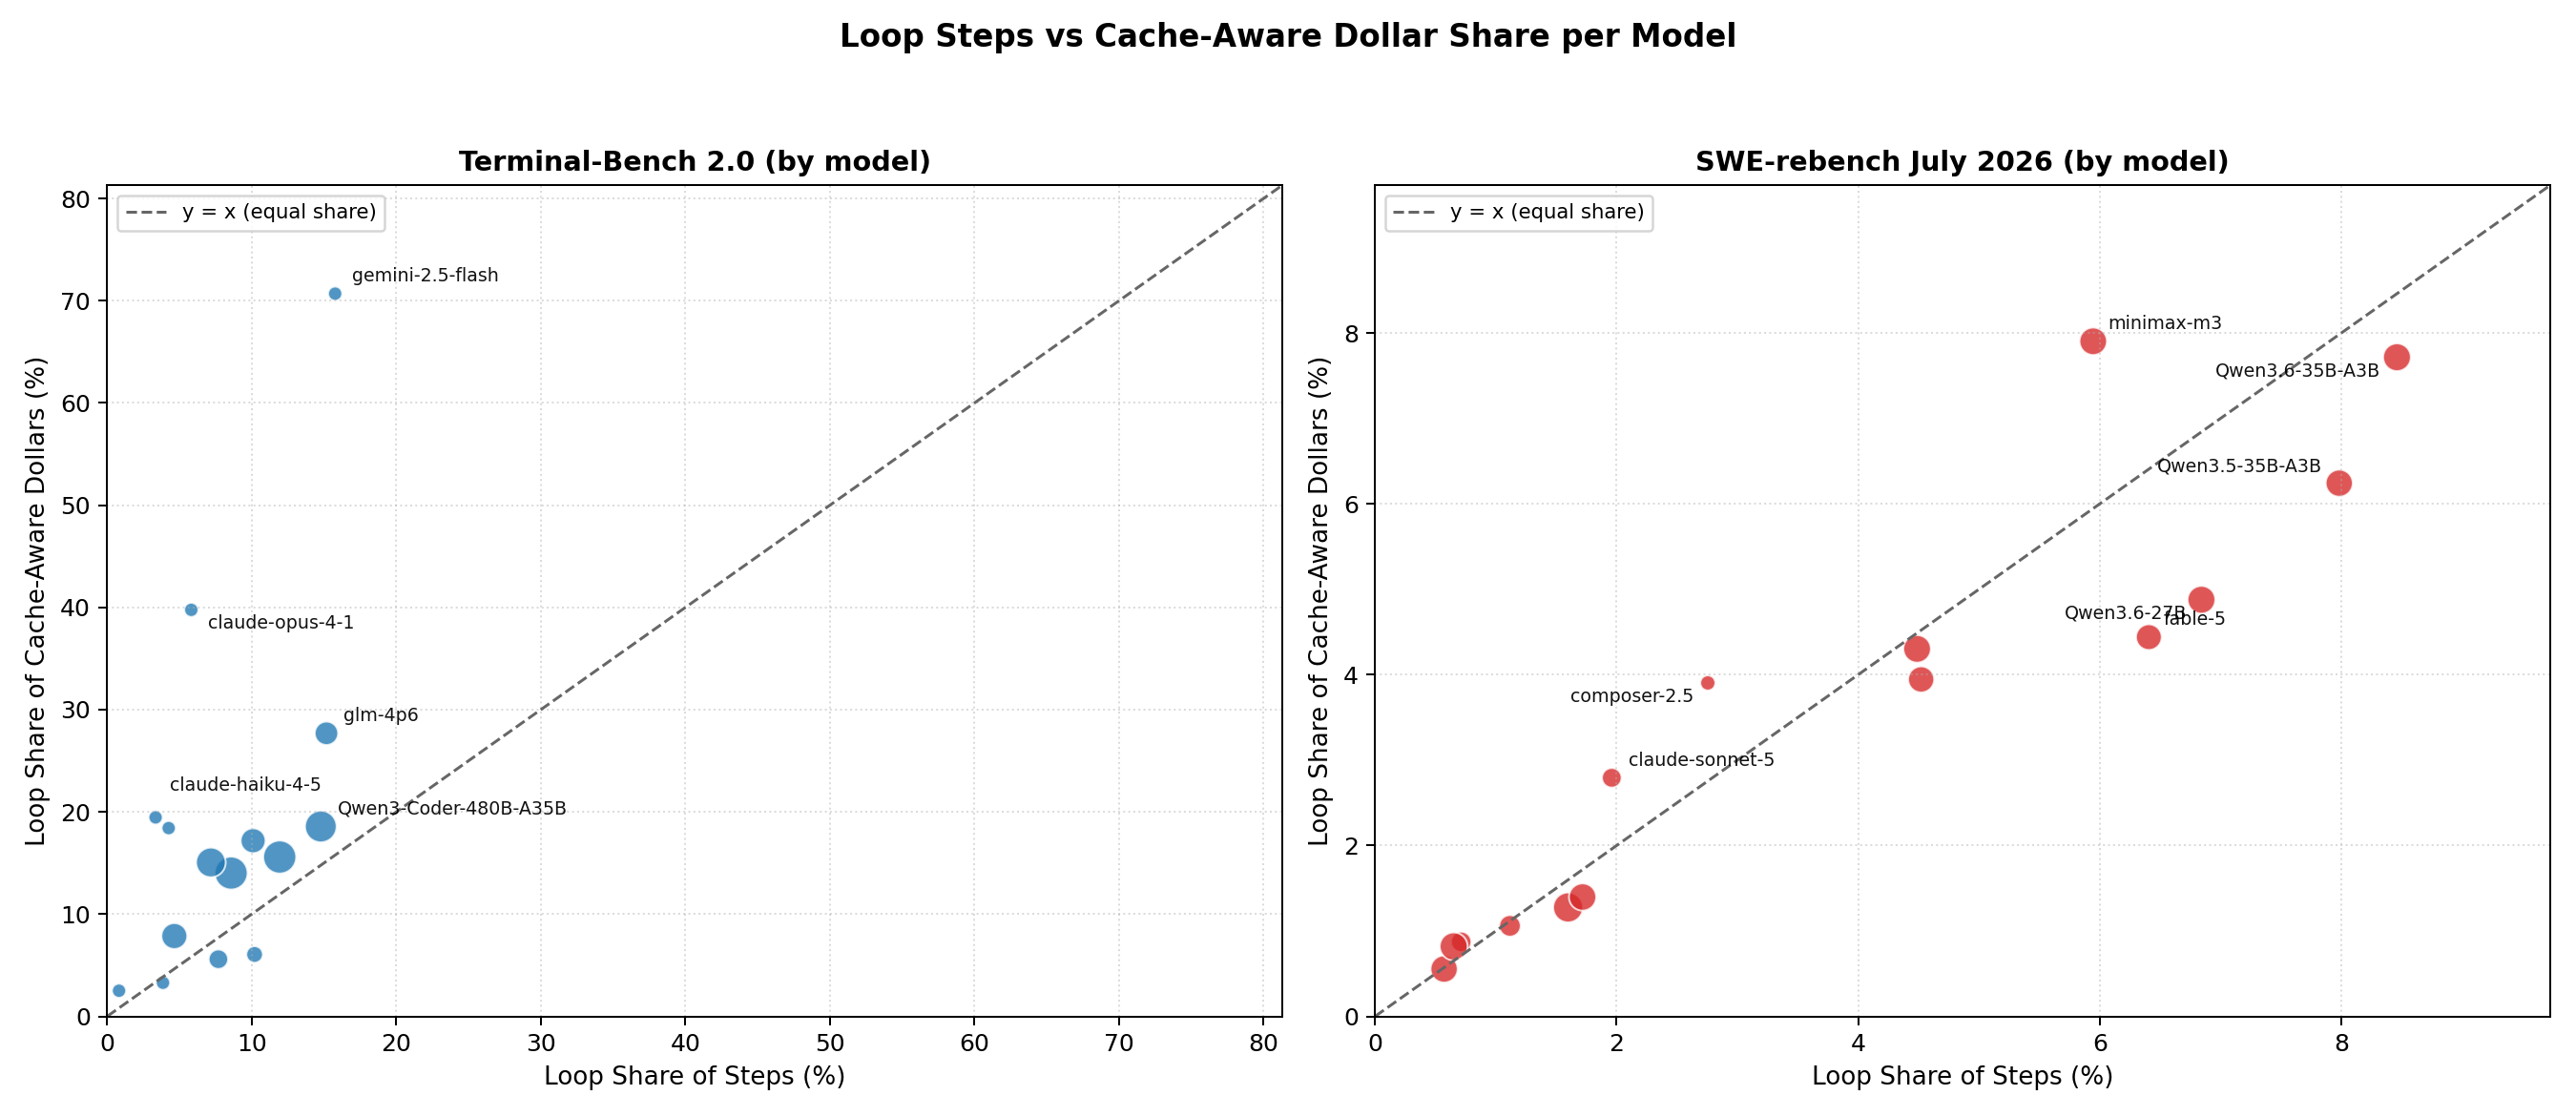

### `detector_savings_vs_false_stop.png`

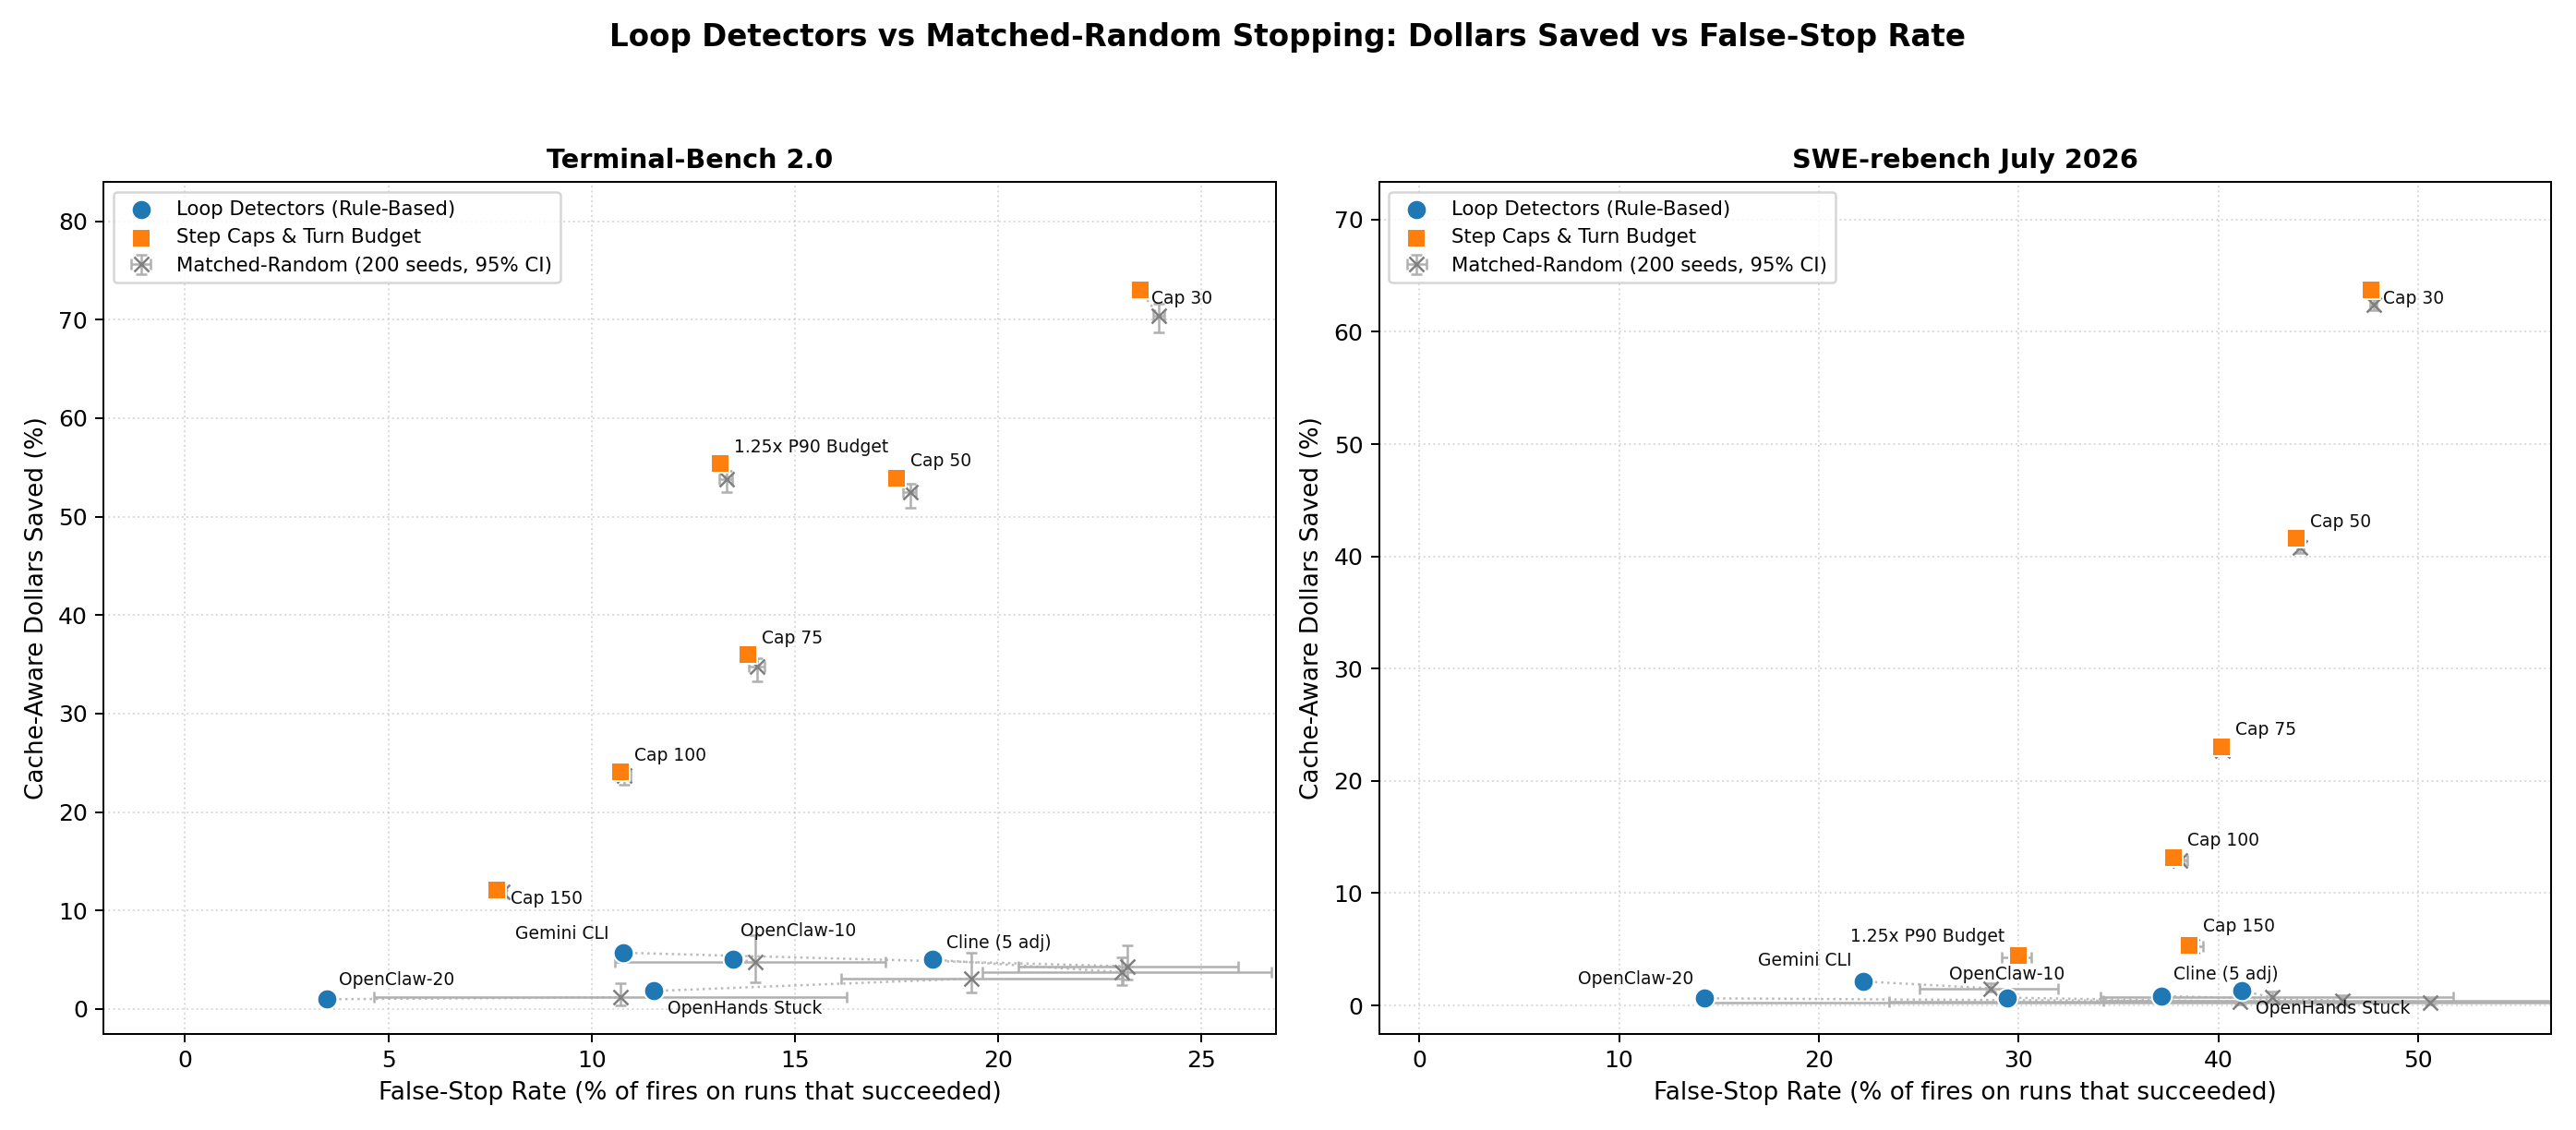

### `loop_prevalence_by_harness.png`

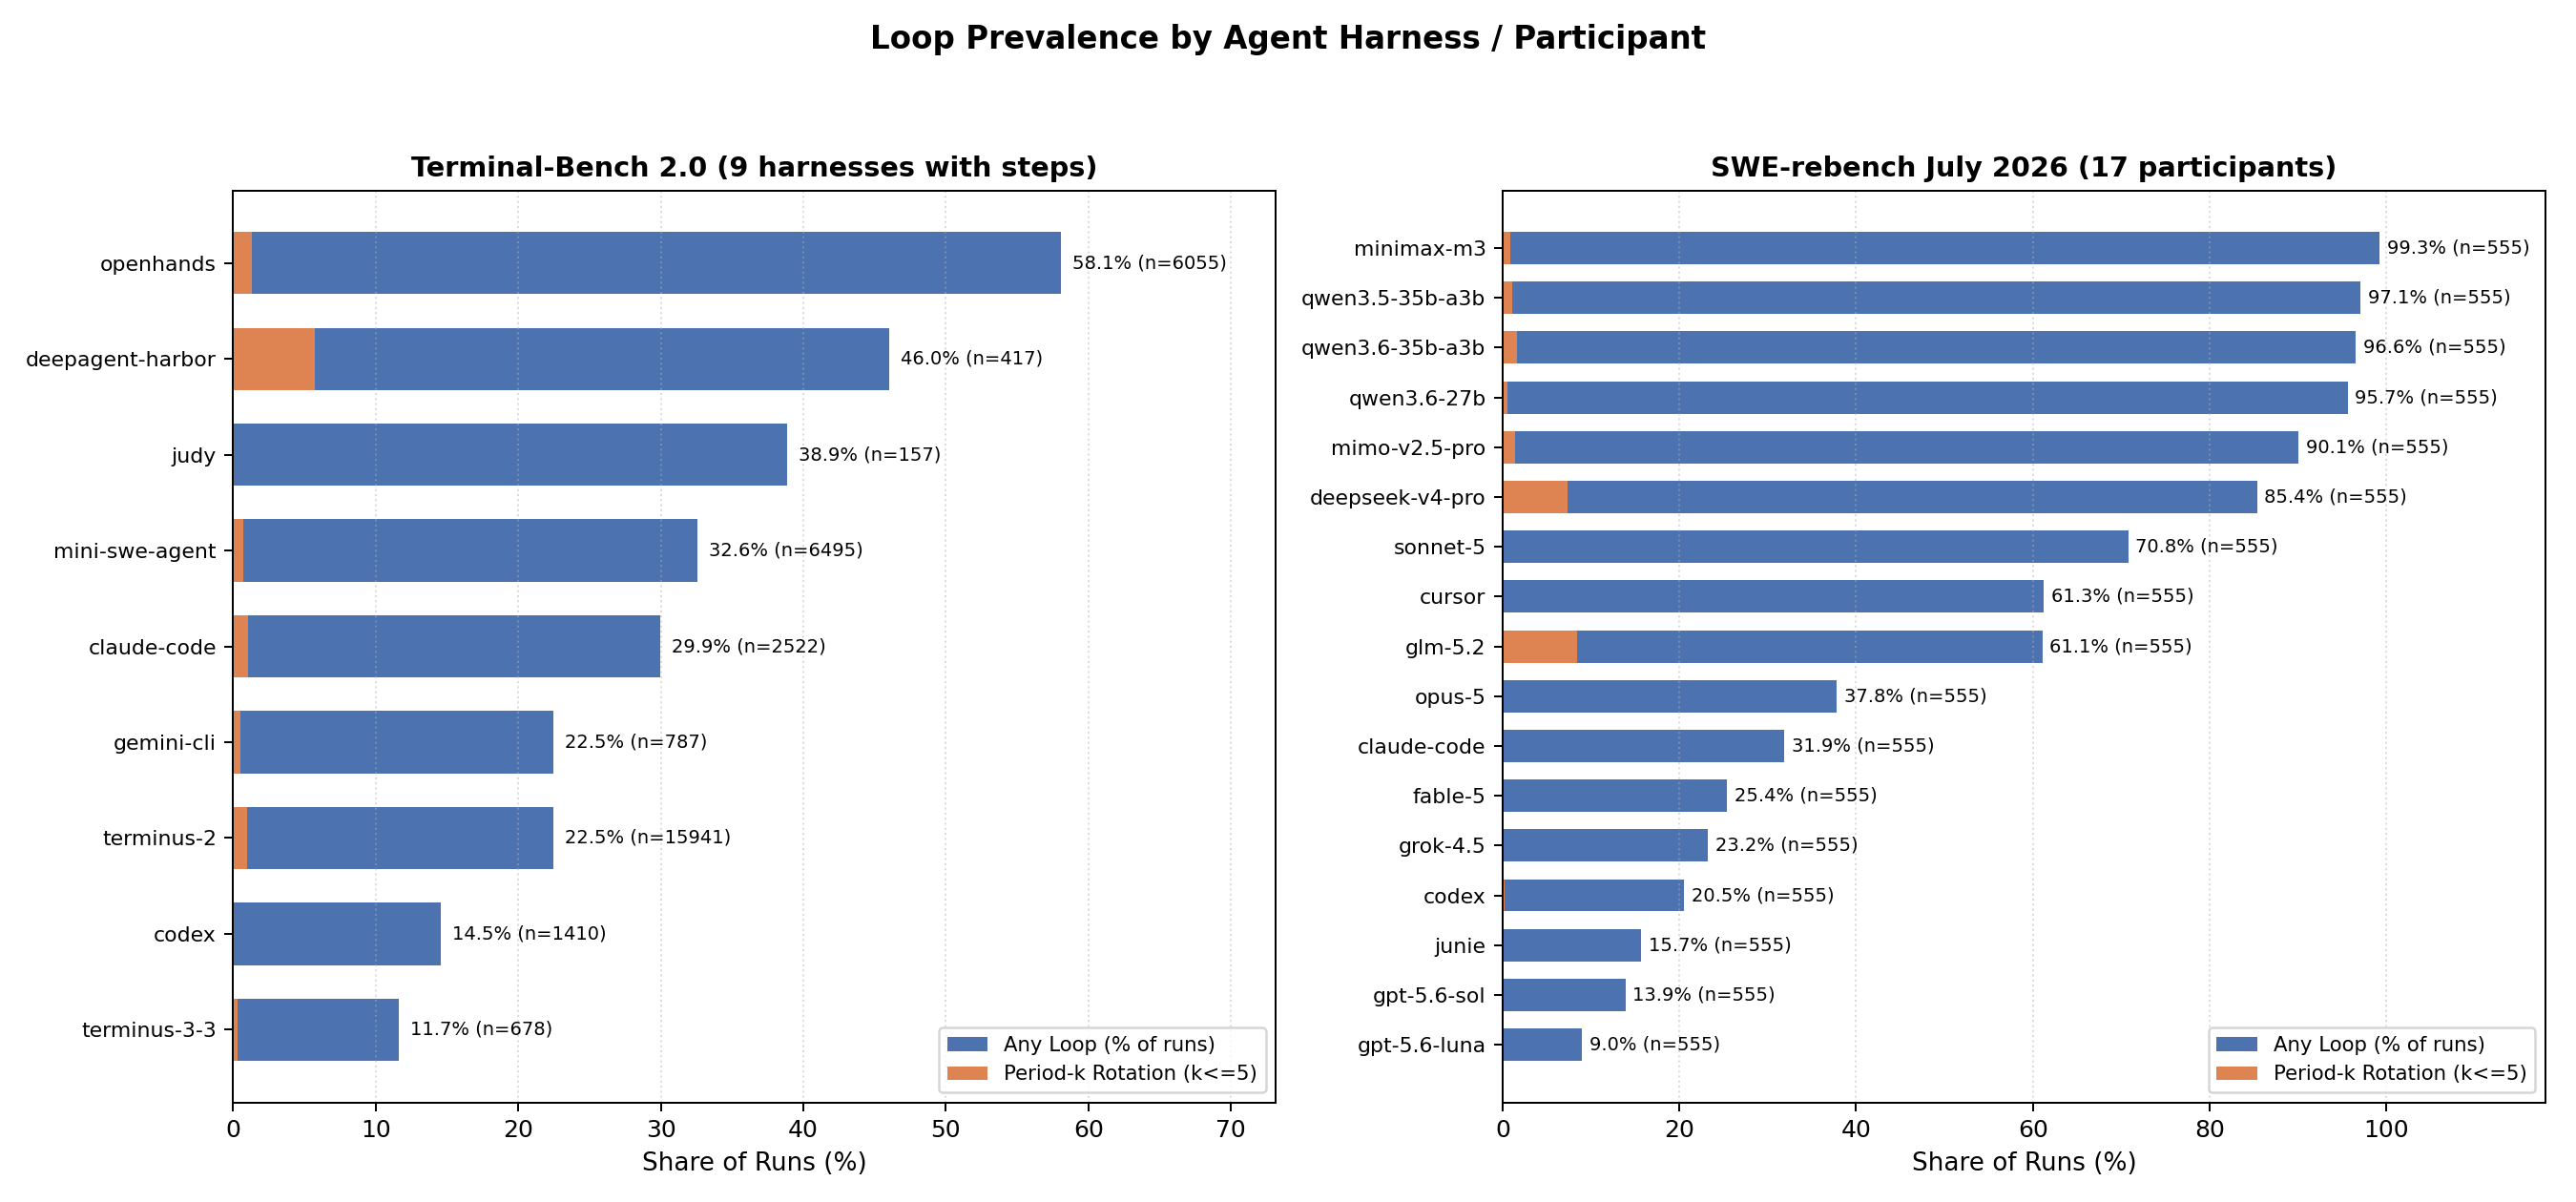

### `loops_per_100_by_model_band.png`

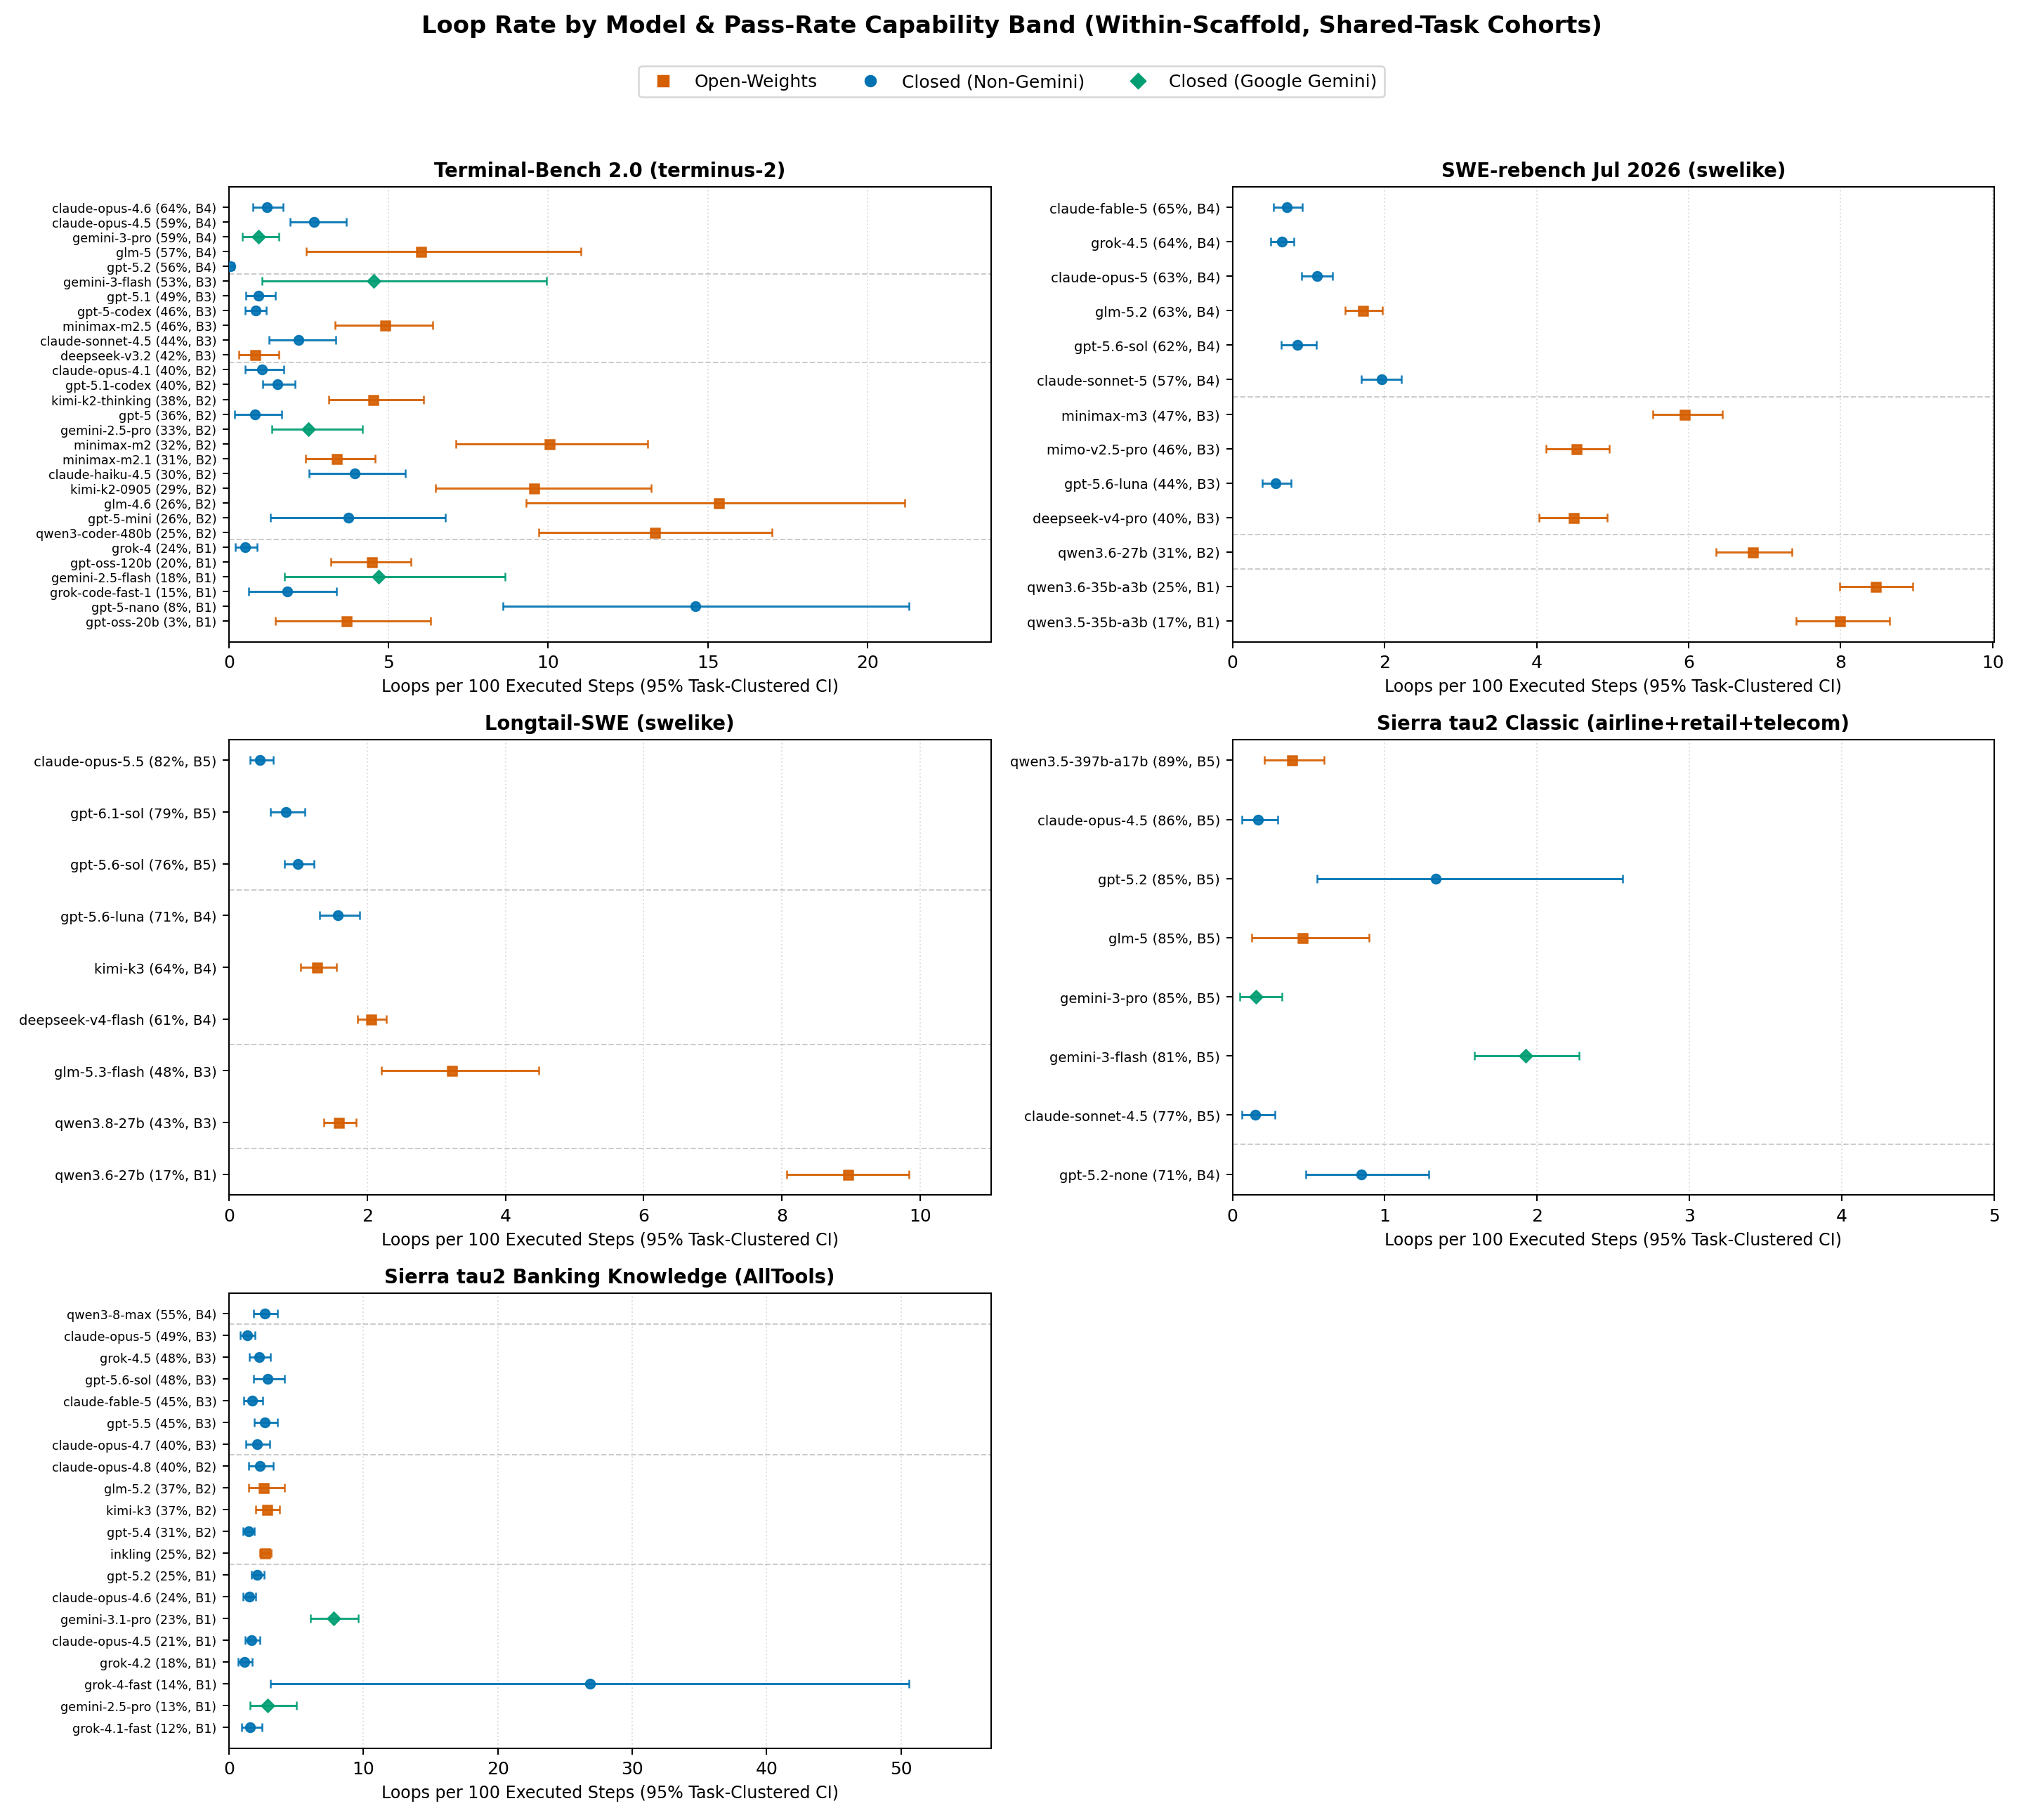

### `open_closed_gap_before_after_matching.png`

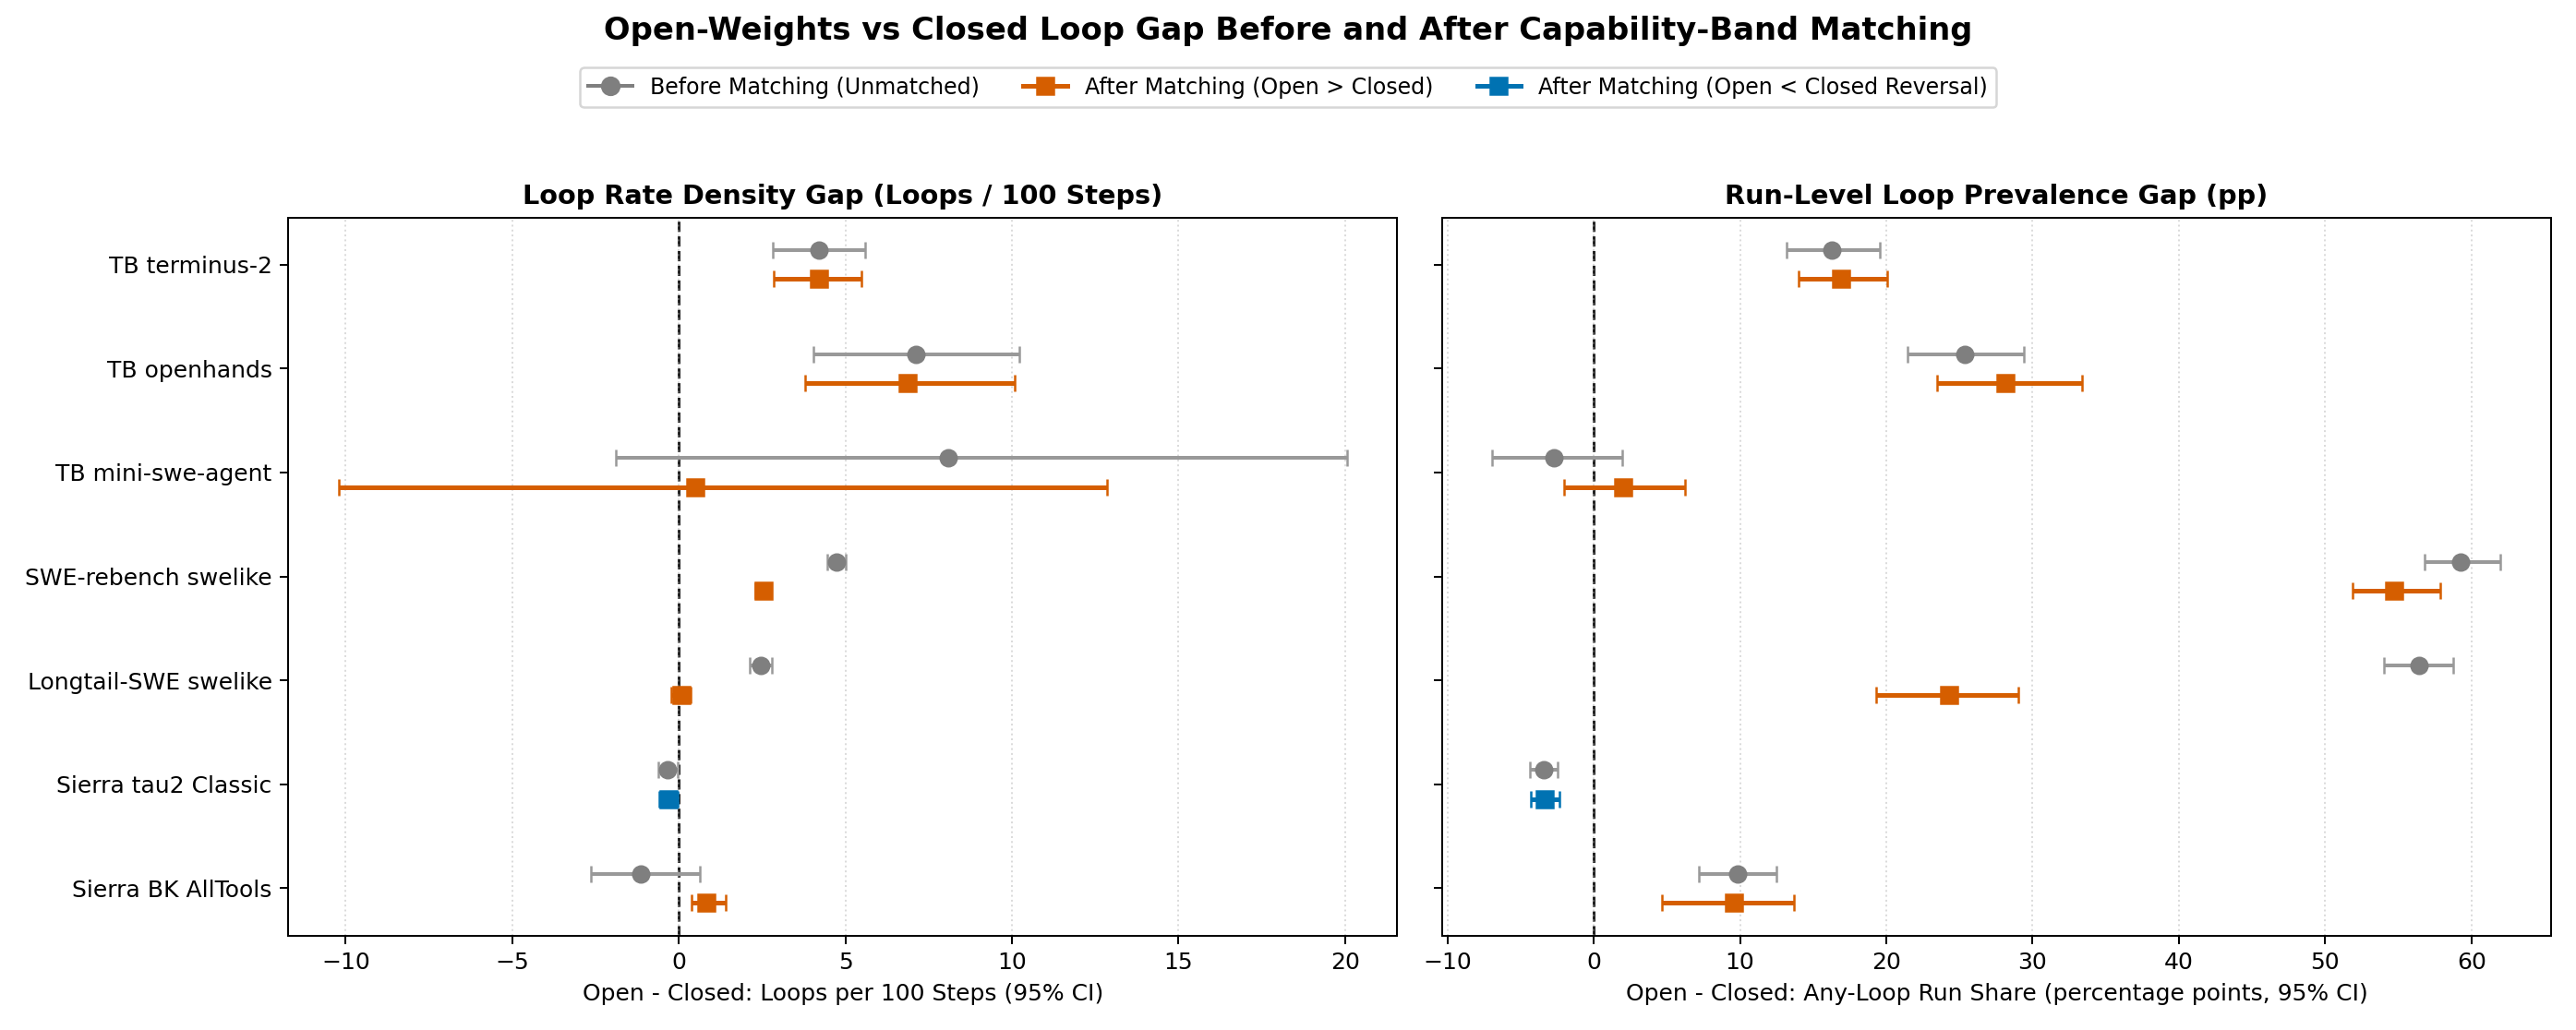

### `open_vs_closed_across_four_datasets.png`

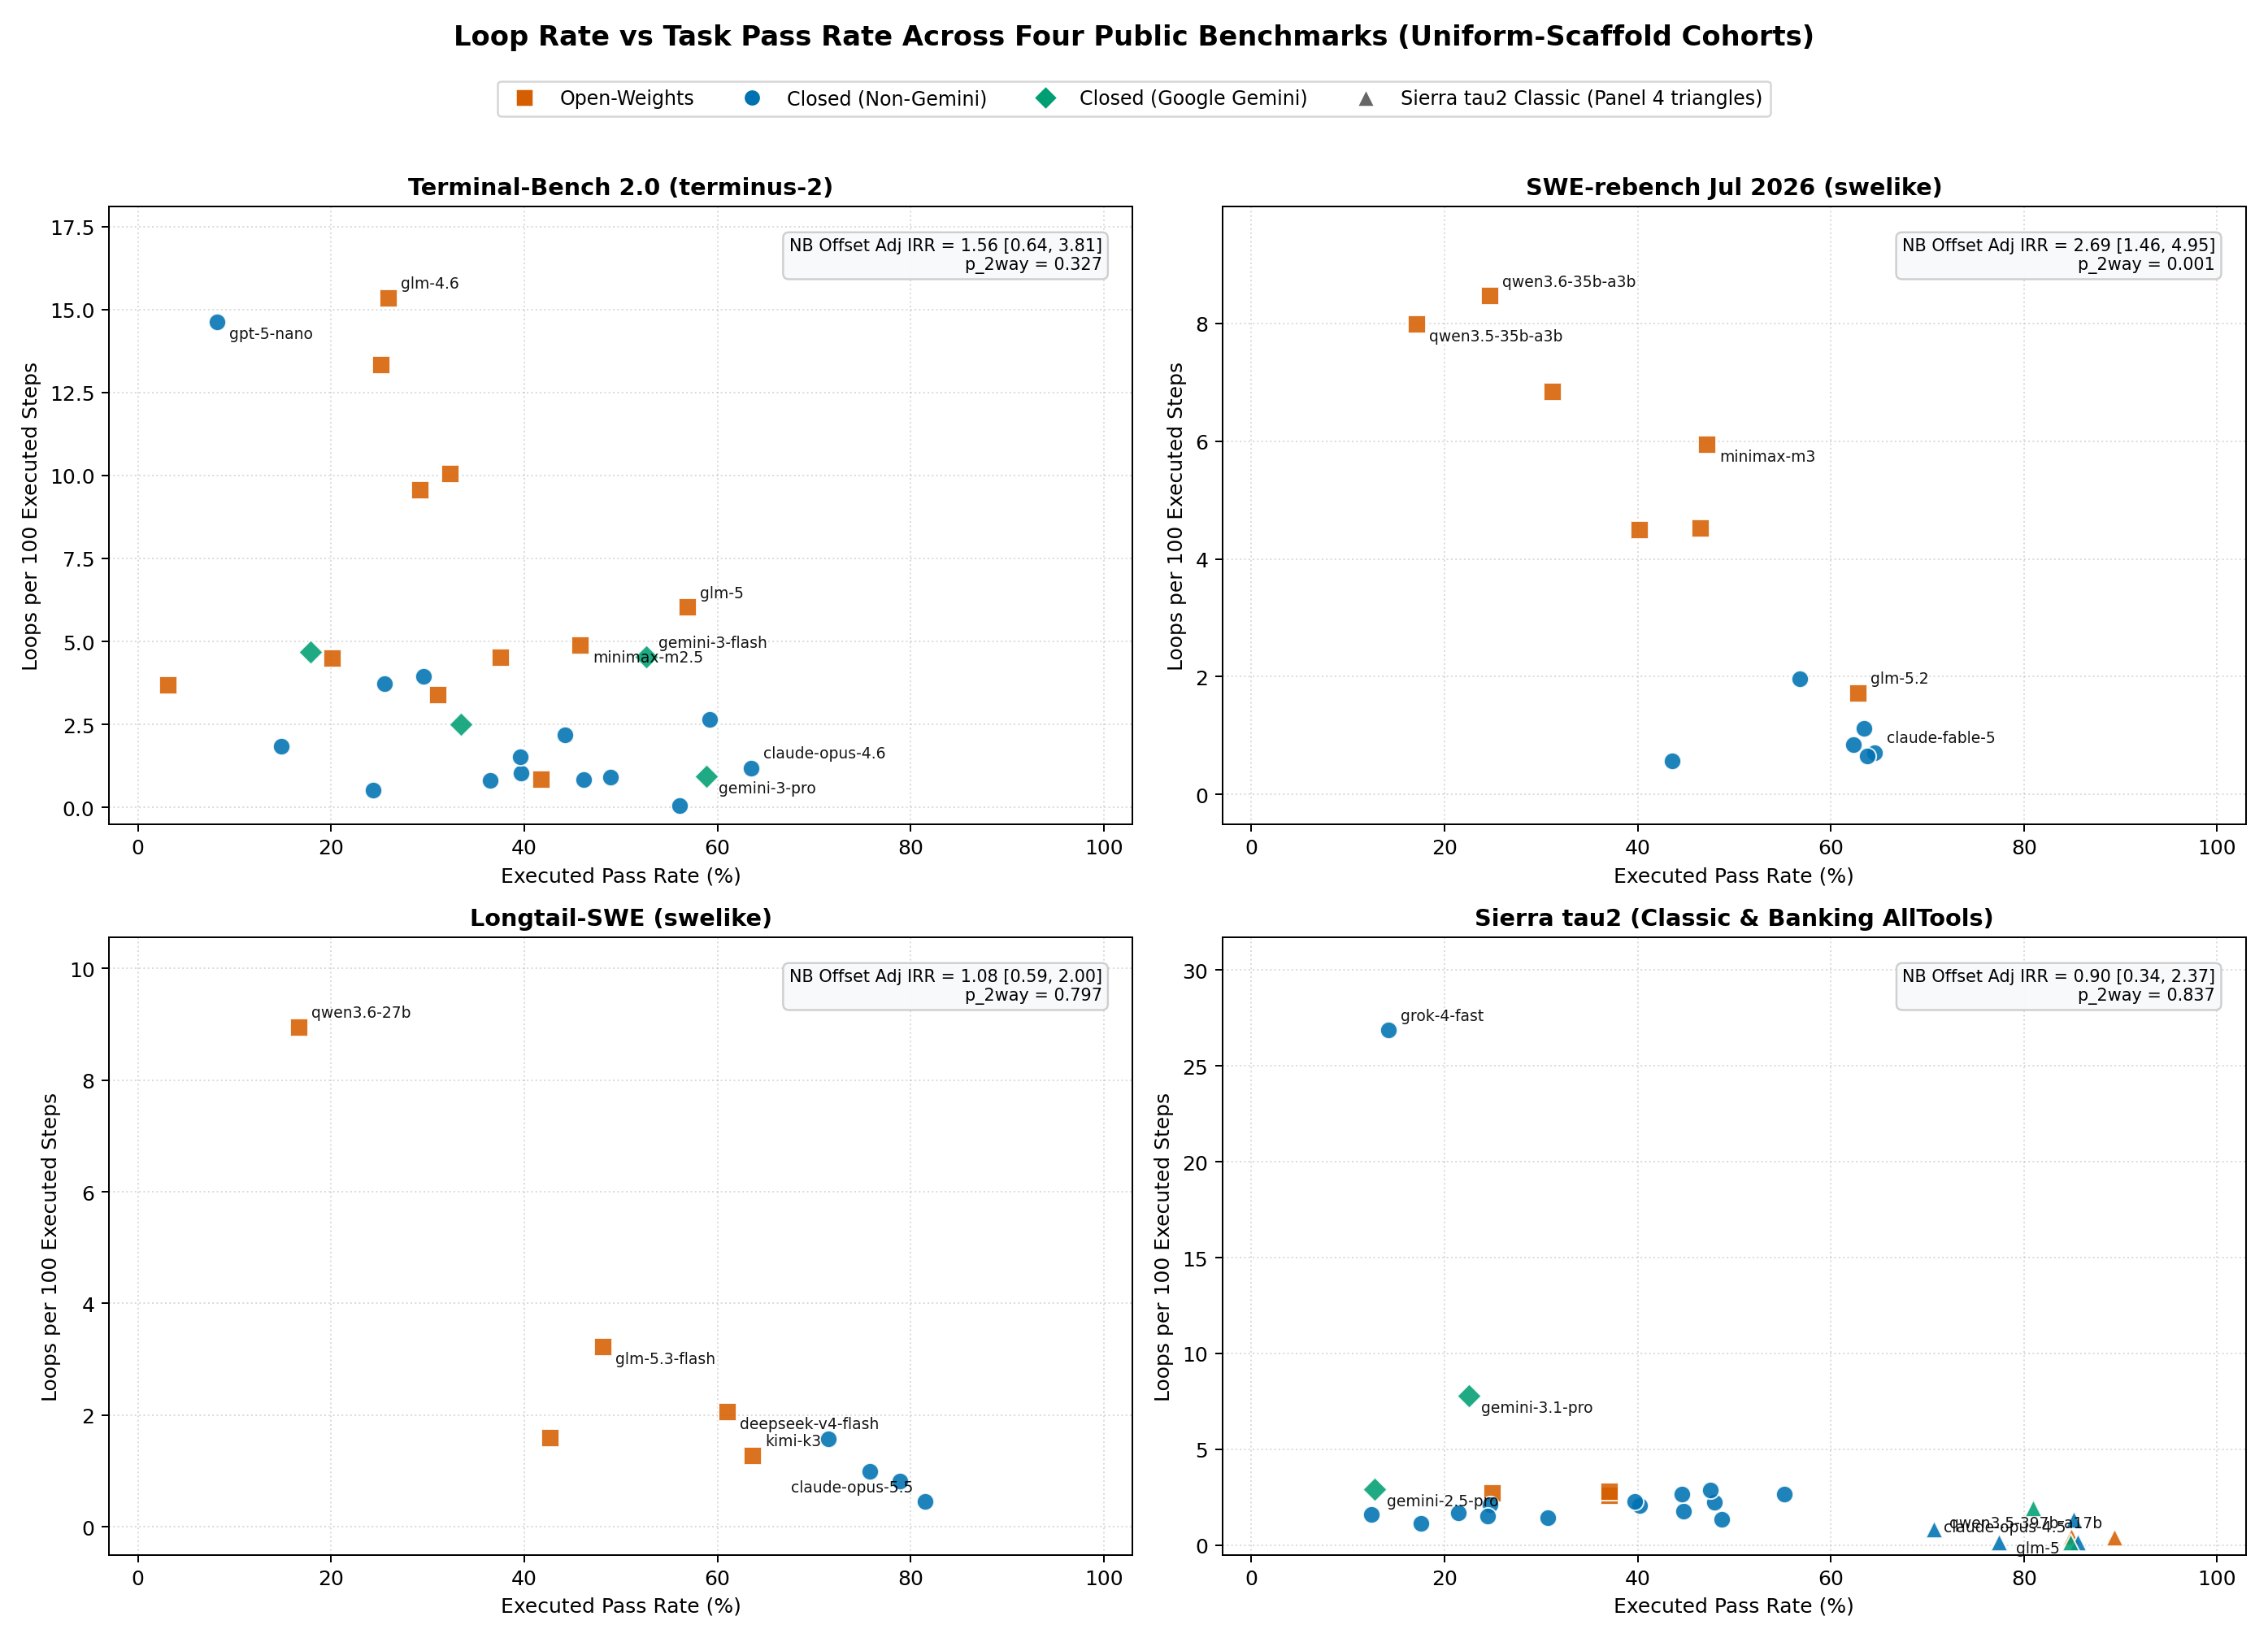

In [ ]:
# @title 2. Execute Study Pipeline & Render Figures
from IPython.display import Image, Markdown, display
import pandas as pd
import run_all

run_all.main()

summary_df = pd.read_csv(ROOT / "results" / "open_vs_closed_summary.csv")
display(summary_df)

for png_name in [
    "step_vs_dollar_share_per_model.png",
    "detector_savings_vs_false_stop.png",
    "loop_prevalence_by_harness.png",
    "loops_per_100_by_model_band.png",
    "open_closed_gap_before_after_matching.png",
    "open_vs_closed_across_four_datasets.png",
]:
    img_path = ROOT / "assets" / png_name
    if img_path.exists():
        display(Markdown(f"### `{png_name}`"))
        display(Image(filename=str(img_path)))


### Q&A
- **How often do AI coding and terminal agents get stuck in pathological loops, and what share of spend do loops consume?** On Terminal-Bench 2.0 (34,462 step-logged trajectories), 31.00% (10,684) of runs contain at least one pathological loop, representing 7.38% of steps (79,344 / 1,075,547) and 17.71% ($589.76 / $3,330.95) of cache-aware spend across 5,011 cost-validated runs. On SWE-rebench July 2026 (9,435 trajectories), 54.99% (5,188) of runs exhibit a loop (4.11% of steps; 2.87% of pooled spend across 6,844 cost-validated runs).
- **Do open-weight models loop more than closed models once compared fairly within identical scaffolds, shared tasks, and capability bands?** Across all 7 uniform-scaffold cohorts, capability-band matching and task-clustered regressions substantially attenuate raw Open-vs-Closed gaps. Pooled within-scaffold Negative Binomial regression (with `log(steps)` offset and two-way `(model_id, task_id)` clustering) yields an adjusted Incidence Rate Ratio (IRR) of 1.31 (95% CI [0.81, 2.13], p = 0.2765), while binary any-loop Logit yields OR = 2.25 (95% CI [1.11, 4.53], p = 0.0236).

### Data Analysis Key Findings
- **Disproportionate Late-Trajectory Cost:** On Terminal-Bench 2.0, loop steps consume 17.71% of cache-aware dollars despite accounting for only 7.38% of steps.
- **Pass-Rate Penalty:** Trajectories containing pathological loops pass at significantly lower rates than loop-free runs across Terminal-Bench 2.0 (27.42% vs 34.27%), SWE-rebench (43.14% vs 59.17%), and τ²-bench (48.36% vs 72.45%).
- **Rule-Based Detectors Miss Multi-Step Cycles:** Standard 5-step exact-repeat detectors (`cline_style`) miss 82.93% (277/334) of `period_k_rotation (k <= 5)` runs on Terminal-Bench 2.0 and 98.33% (118/120) on SWE-rebench.

### Insights or Next Steps
- **Upgrade Harness Loop Detectors:** Combine canonicalized period-k (k <= 5) cycle and A-B-A thrash detection with adaptive `1.25x P90` harness turn budgets.
- **Remote CPU Execution:** Use `colab exec -s <session> --timeout 1800 -f agent_loops_colab_cpu.ipynb` to run future refreshes entirely on Google Colab CPUs.